# **END TO END SALES DATA ANALYTICS**
**Project Roadmap**

1. Data loading and understanding

2. Initial data quality checks

3. Data cleaning and feature engineering

4. Exploratory Data Analysis (EDA)

5. Data visualization using Matplotlib and Seaborn

6. Business insights and conclusions

7. Power BI dashboard development

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("retail_sales_dataset.csv")

# Display first 5 rows
print(df.head())

   Transaction ID        Date Customer ID  Gender  Age Product Category  \
0               1  2023-11-24     CUST001    Male   34           Beauty   
1               2  2023-02-27     CUST002  Female   26         Clothing   
2               3  2023-01-13     CUST003    Male   50      Electronics   
3               4  2023-05-21     CUST004    Male   37         Clothing   
4               5  2023-05-06     CUST005    Male   30           Beauty   

   Quantity  Price per Unit  Total Amount  
0         3              50           150  
1         2             500          1000  
2         1              30            30  
3         1             500           500  
4         2              50           100  


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [4]:
df.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
# Check missing values
print(df.isnull().sum())

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [7]:
df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce"
    # errors="coerce": Converts invalid dates into NaT (Not a Time)
)
print(df["Date"].dtype)

datetime64[ns]


In [8]:
print(df["Date"].isnull().sum())

0


In [9]:
# Extract year
df["Year"] = df["Date"].dt.year

# Extract month
df["Month"] = df["Date"].dt.month

# Extract month name
df["Month Name"] = df["Date"].dt.month_name()

# Extract day
df["Day"] = df["Date"].dt.day

# Extract weekday
df["Weekday"] = df["Date"].dt.day_name()

In [10]:
print(df[["Date", "Year", "Month",
          "Month Name", "Day", "Weekday"]])

          Date  Year  Month Month Name  Day    Weekday
0   2023-11-24  2023     11   November   24     Friday
1   2023-02-27  2023      2   February   27     Monday
2   2023-01-13  2023      1    January   13     Friday
3   2023-05-21  2023      5        May   21     Sunday
4   2023-05-06  2023      5        May    6   Saturday
..         ...   ...    ...        ...  ...        ...
995 2023-05-16  2023      5        May   16    Tuesday
996 2023-11-17  2023     11   November   17     Friday
997 2023-10-29  2023     10    October   29     Sunday
998 2023-12-05  2023     12   December    5    Tuesday
999 2023-04-12  2023      4      April   12  Wednesday

[1000 rows x 6 columns]


**Date Feature Engineering: Here we achieved:-**

Year: Yearly sales analysis

Month: Monthly revenue analysis

Month Name: Sales trend visualization

Day: Daily sales analysis

Weekday: Identify the busiest sales days

In [11]:
print("Gender:", df["Gender"].unique())

print("Product Categories:",
      df["Product Category"].unique())

print("Customer Count:",
      df["Customer ID"].nunique())
# the same customer can make multiple purchases, so their Customer ID may appear several times.
# We want to know how many different customers purchased products, not how many times customer IDs appear.

Gender: ['Male' 'Female']
Product Categories: ['Beauty' 'Clothing' 'Electronics']
Customer Count: 1000


.count(): Counts non-null values

.unique(): Displays unique values

.nunique(): Counts unique values

In [12]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
import warnings
warnings.filterwarnings("ignore")
# df["Gender"] = le.fit_transform(df["Gender"])
# df["Product Category"] = le.fit_transform(df["Product Category"])
df["Customer ID"] = le.fit_transform(df["Customer ID"])

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    1000 non-null   int64         
 1   Date              1000 non-null   datetime64[ns]
 2   Customer ID       1000 non-null   int64         
 3   Gender            1000 non-null   object        
 4   Age               1000 non-null   int64         
 5   Product Category  1000 non-null   object        
 6   Quantity          1000 non-null   int64         
 7   Price per Unit    1000 non-null   int64         
 8   Total Amount      1000 non-null   int64         
 9   Year              1000 non-null   int32         
 10  Month             1000 non-null   int32         
 11  Month Name        1000 non-null   object        
 12  Day               1000 non-null   int32         
 13  Weekday           1000 non-null   object        
dtypes: datetime64[ns](1), int

In [14]:
# 1. Total Revenue
print("Total Revenue:", df["Total Amount"].sum())

# 2. Total Transactions
print("Total Transactions:", df["Transaction ID"].nunique())

# 3. Total Customers
print("Total Customers:", df["Customer ID"].nunique())

# 4. Total Quantity Sold
print("Total Quantity Sold:", df["Quantity"].sum())

# 5. Average Order Value
aov = df["Total Amount"].sum() / df["Transaction ID"].nunique()

print("Average Order Value:", aov)

Total Revenue: 456000
Total Transactions: 1000
Total Customers: 1000
Total Quantity Sold: 2514
Average Order Value: 456.0


1. The retail business generated 456,000 in total sales revenue.
This represents the total sales value across all 1,000 transactions.

2. The dataset contains 1,000 unique transactions.
Each transaction represents one recorded purchase.
This helps measure the overall sales activity.

3. There are 1,000 unique customers.
Since transactions and unique customers are both 1,000, each customer appears to have made exactly one transaction in this dataset.
This suggests there are no repeat purchases recorded in the dataset.

4. The business sold 2,514 product units.
On average, approximately 2.51 units were purchased per transaction.
This helps understand product demand.

5. Customers spent an average of 456 per transaction.

In [15]:
# Category-wise sales analysis: let's find out which product category generates the highest revenue.
category_sales = df.groupby(
    "Product Category"
)["Total Amount"].sum().sort_values(
    ascending=False
)

print(category_sales)

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


Category-wise revenue analysis shows that Electronics generated the highest revenue of 156,905, followed by Clothing at 155,580 and Beauty at 143,515. Electronics contributed approximately 34.41% of total revenue, making it the leading product category. However, the revenue distribution across all three categories is relatively balanced.

In [16]:
# quantity sold by each category:
category_quantity = df.groupby(
    "Product Category"
)["Quantity"].sum()

print(category_quantity)

Product Category
Beauty         771
Clothing       894
Electronics    849
Name: Quantity, dtype: int64


Category-wise quantity analysis reveals that Clothing recorded the highest sales volume with 894 units, followed by Electronics with 849 units and Beauty with 771 units. Although Clothing sold the highest number of units, Electronics generated the highest revenue. This indicates differences in revenue generated per unit across product categories.

In [17]:
# calculate the number of transactions per category:
category_transactions = df.groupby(
    "Product Category"
)["Transaction ID"].nunique()

print(category_transactions)


Product Category
Beauty         307
Clothing       351
Electronics    342
Name: Transaction ID, dtype: int64


Category-wise analysis indicates that Clothing leads in transaction volume with 351 transactions and 894 units sold. Electronics generates the highest revenue of 156,905 despite recording 342 transactions and 849 units sold. Beauty ranks third across all three metrics. These findings help identify category-level sales performance and support inventory and marketing decisions.

In [18]:
# Gender-wise sales analysis:
# A. Revenue by gender:-

gender_revenue = df.groupby(
    "Gender"
)["Total Amount"].sum().sort_values(ascending=False)

print(gender_revenue)

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


*   Female customers generated 9,680 more revenue than male customers.
*   The revenue contribution is relatively balanced between both genders.
*   Female customers are the slightly higher revenue-generating group in this dataset.

In [19]:
# B. Quantity sold by gender

gender_quantity = df.groupby(
    "Gender"
)["Quantity"].sum()

print(gender_quantity)

Gender
Female    1298
Male      1216
Name: Quantity, dtype: int64


Gender-wise quantity analysis indicates that female customers purchased 1,298 units, accounting for approximately 51.63% of total quantity sold. Male customers purchased 1,216 units, contributing 48.37%. Female customers purchased 82 more units than male customers, indicating slightly higher purchasing volume among female customers.

In [20]:

# *Revenue: Female customers generated more revenue.
# *Quantity: Female customers purchased more units.
# *Transactions: Now we will identify which gender made more purchases.

gender_transactions = df.groupby(
    "Gender"
)["Transaction ID"].nunique().sort_values(
    ascending=False
)

print(gender_transactions)

Gender
Female    510
Male      490
Name: Transaction ID, dtype: int64


Gender-wise analysis reveals that female customers contribute slightly more to overall retail sales than male customers. Female customers generated 232,840 in revenue, purchased 1,298 units and recorded 510 transactions. Male customers generated 223,160 in revenue, purchased 1,216 units and recorded 490 transactions. This indicates that female customers have a slightly higher contribution across all three sales metrics, while the overall distribution remains relatively balanced.

In [21]:
# Monthly sales analysis:  let's analyze sales trends across different months:-
# A. Monthly revenue:

monthly_sales = df.groupby(
    "Month Name"
)["Total Amount"].sum()

print(monthly_sales)

Month Name
April        33870
August       36960
December     44690
February     44060
January      36980
July         35465
June         36715
March        28990
May          53150
November     34920
October      46580
September    23620
Name: Total Amount, dtype: int64


In [22]:
# to display months in calendar order:

monthly_sales = df.groupby(
    "Month"
)["Total Amount"].sum().sort_index()

print(monthly_sales)

Month
1     36980
2     44060
3     28990
4     33870
5     53150
6     36715
7     35465
8     36960
9     23620
10    46580
11    34920
12    44690
Name: Total Amount, dtype: int64


In [23]:
# B. Monthly quantity sold:

monthly_quantity = df.groupby(
    "Month"
)["Quantity"].sum().sort_index()

print(monthly_quantity)

Month
1     199
2     214
3     194
4     214
5     259
6     197
7     176
8     227
9     170
10    252
11    205
12    207
Name: Quantity, dtype: int64


In [24]:
# C. Monthly transactions:

monthly_transactions = df.groupby(
    "Month"
)["Transaction ID"].nunique().sort_index()

print(monthly_transactions)

Month
1      78
2      85
3      73
4      86
5     105
6      77
7      72
8      94
9      65
10     96
11     78
12     91
Name: Transaction ID, dtype: int64


Monthly sales analysis reveals that May was the best-performing month, generating 53,150 in revenue, selling 259 units and recording 105 transactions. September was the weakest month, with revenue of 23,620, quantity sold of 170 units and 65 transactions. October also demonstrated strong sales performance. These findings help identify monthly sales fluctuations and support better inventory planning and promotional strategies.

In [25]:
#Monthly Sales Trend Analysis:


print("Highest Sales Month:", monthly_sales.idxmax())
print("Highest Monthly Sales:", monthly_sales.max())

print("Lowest Sales Month:", monthly_sales.idxmin())
print("Lowest Monthly Sales:", monthly_sales.min())

Highest Sales Month: 5
Highest Monthly Sales: 53150
Lowest Sales Month: 9
Lowest Monthly Sales: 23620


The monthly sales analysis revealed that May recorded the highest revenue of ₹53,150, while September had the lowest revenue of ₹23,620. The difference between these months was ₹29,530, indicating considerable variation in monthly sales performance. The business could investigate seasonal demand, promotional activities and customer purchasing patterns to understand the factors influencing these fluctuations.

In [26]:
# Weekday-wise sales analysis:

# A. Revenue by weekday:
weekday_revenue = df.groupby(
    "Weekday"
)["Total Amount"].sum().sort_values(ascending=False)

print(weekday_revenue)


Weekday
Saturday     78815
Monday       70250
Tuesday      69440
Friday       66290
Wednesday    58770
Sunday       58600
Thursday     53835
Name: Total Amount, dtype: int64


In [27]:
# B. Quantity by weekday:
weekday_quantity = df.groupby(
    "Weekday"
)["Quantity"].sum().sort_values(ascending=False)

print(weekday_quantity)

Weekday
Tuesday      397
Monday       385
Friday       373
Saturday     373
Wednesday    356
Sunday       329
Thursday     301
Name: Quantity, dtype: int64


In [28]:
# C. Transactions by weekday:
weekday_transactions = df.groupby(
    "Weekday"
)["Transaction ID"].nunique().sort_values(ascending=False)

print(weekday_transactions)

Weekday
Tuesday      161
Saturday     150
Monday       146
Friday       143
Wednesday    139
Sunday       138
Thursday     123
Name: Transaction ID, dtype: int64


Weekday-wise sales analysis reveals that Saturday generated the highest revenue of 78,815, while Tuesday recorded the highest quantity sold of 397 units and the highest transaction count of 161. Thursday showed the weakest performance across all three metrics, generating 53,835 in revenue, selling 301 units and recording 123 transactions. These findings help identify variations in customer purchasing activity across different weekdays.

In [29]:
# Customer analysis: customer purchasing behaviour:-

# A. Top 10 customers by revenue:
top_customers = df.groupby(
    "Customer ID"
)["Total Amount"].sum().sort_values(
    ascending=False
).head(10)

print(top_customers)

# Identify high-value customers.
# Understand which customers purchase more products.
# Identify age groups contributing more revenue.
# Develop customer-focused marketing strategies.

Customer ID
14     2000
412    2000
970    2000
547    2000
281    2000
416    2000
420    2000
927    2000
447    2000
342    2000
Name: Total Amount, dtype: int64


The top 10 customers generated 2,000 each.
All 10 customers have the same revenue contribution.
There is no single highest-revenue customer among these 10.
The dataset shows equal revenue contributions at the top of this ranking.

In [30]:
# B. Top 10 customers by quantity:
top_quantity_customers = df.groupby(
    "Customer ID"
)["Quantity"].sum().sort_values(
    ascending=False
).head(10)

print(top_quantity_customers)

Customer ID
7      4
9      4
13     4
726    4
729    4
731    4
735    4
736    4
740    4
22     4
Name: Quantity, dtype: int64


The highest quantity purchased by an individual customer is 4 units.
Multiple customers share the same purchasing quantity.
There is no unique highest-volume customer.
This indicates that customer-level purchase quantities are limited in this dataset.

In [31]:
# C. Customer age analysis:
age_sales = df.groupby(
    "Age"
)["Total Amount"].sum().sort_values(
    ascending=False
)

print(age_sales.head(10))

Age
43    17970
34    16785
51    16065
19    14870
26    13980
22    13700
46    13090
21    12585
47    12505
37    11650
Name: Total Amount, dtype: int64


Age 43 generated the highest revenue of 17,970.

Age 34 ranked second with 16,785.

Age 51 ranked third with 16,065.

Customers aged 19 and 22 also contributed significantly.

Revenue is distributed across several age groups rather than being concentrated in one age.

In [32]:
# Customer Transaction Analysis:

print("Unique Customers:",
      df["Customer ID"].nunique())

print("Total Transactions:",
      df["Transaction ID"].nunique())

print("Customers with multiple transactions:")

print(
    df.groupby("Customer ID")["Transaction ID"]
      .nunique()
      .value_counts()
)



Unique Customers: 1000
Total Transactions: 1000
Customers with multiple transactions:
Transaction ID
1    1000
Name: count, dtype: int64


### Customer Transaction Analysis

The analysis identified 1,000 unique customers and 1,000 unique transactions. Each customer completed exactly one transaction, indicating that there were no repeat purchases in the dataset. The repeat purchase rate was 0%. This finding highlights an opportunity to investigate customer retention and develop strategies to encourage repeat purchases, such as loyalty programmes and targeted promotions.

In [33]:
# Customer Spending Analysis

customer_spending = (
    df.groupby("Customer ID")["Total Amount"]
      .sum()
)

print("Average Customer Spending:",
      round(customer_spending.mean(), 2))

print("Highest Customer Spending:",
      customer_spending.max())

print("Lowest Customer Spending:",
      customer_spending.min())

Average Customer Spending: 456.0
Highest Customer Spending: 2000
Lowest Customer Spending: 25


The analysis shows that the average customer spending is ₹456. The highest customer spending is ₹2,000, while the lowest is ₹25. This indicates variation in customer spending behaviour. The business can use this information to identify high-value customers and develop targeted marketing strategies to encourage higher spending.

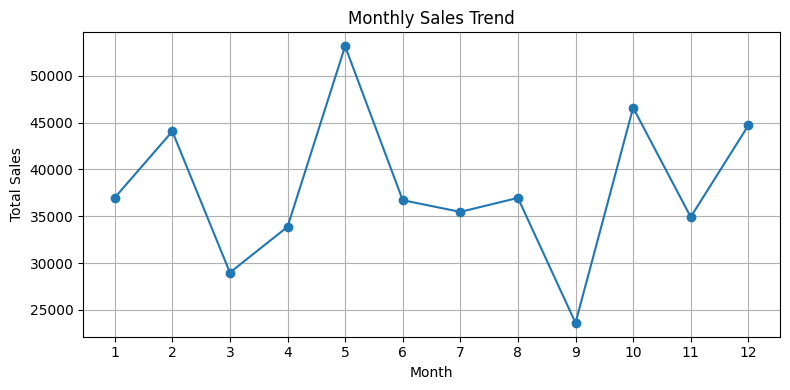

In [34]:
# Visualize Monthly Sales:

import matplotlib.pyplot as plt

monthly_sales.plot(
    kind="line",
    marker="o",
    figsize=(8, 4),
    title="Monthly Sales Trend"
)

plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

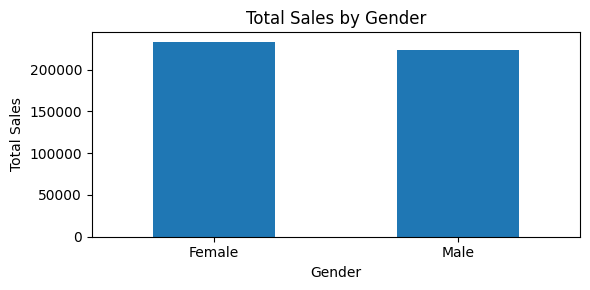

In [35]:
# Sales by Gender:

import matplotlib.pyplot as plt

gender_revenue.plot(
    kind="bar",
    figsize=(6, 3),
    title="Total Sales by Gender",
    rot=0
)

plt.xlabel("Gender")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

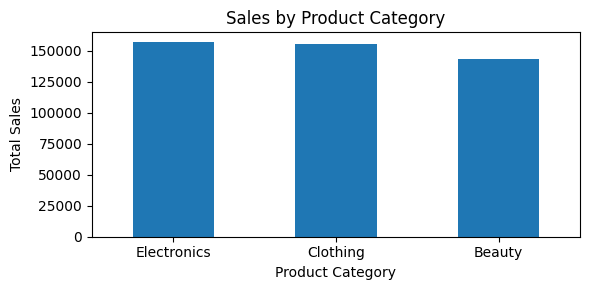

In [36]:
# category sales:

import matplotlib.pyplot as plt

category_sales.plot(
    kind="bar",
    figsize=(6, 3),
    title="Sales by Product Category",
    rot=0
)

plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

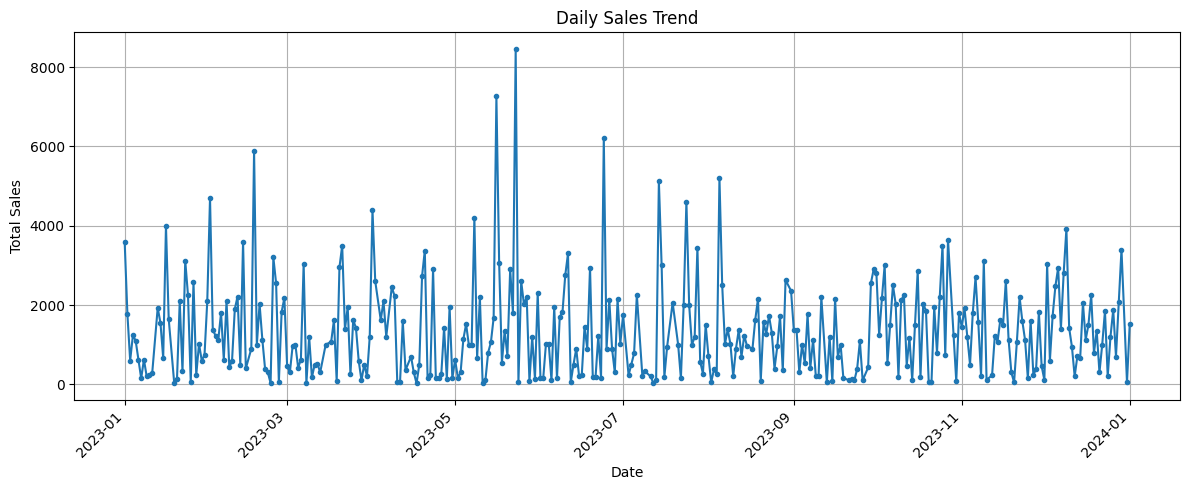

In [37]:
# Daily Sales Trend:

import matplotlib.pyplot as plt

# Group by 'Date' to aggregate total sales per day
daily_sales = df.groupby("Date")["Total Amount"].sum()

plt.figure(figsize=(12, 5))

daily_sales.plot(
    kind="line",
    marker="o",
    markersize=3
)

plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

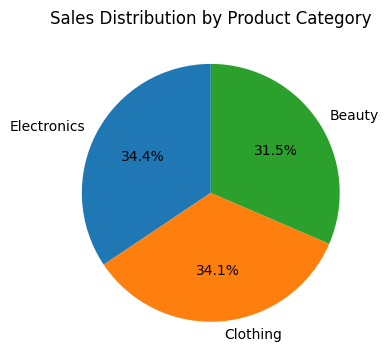

In [38]:
# Sales by Payment Method:

import matplotlib.pyplot as plt

plt.figure(figsize=(4,4))

# Using category_sales as there is no payment method in this dataset
category_sales.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Sales Distribution by Product Category")
plt.ylabel("")
plt.tight_layout()
plt.show()

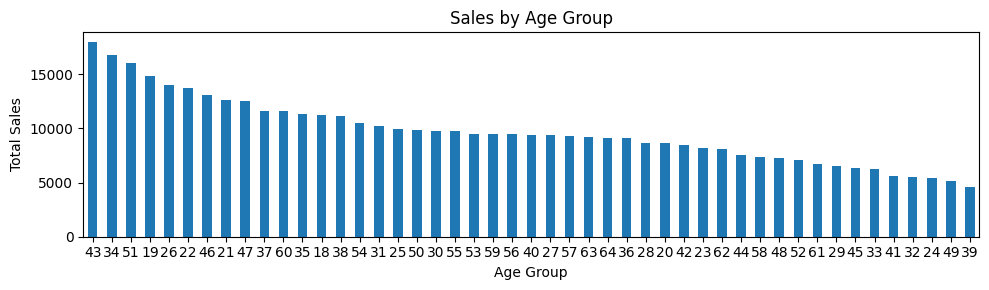

In [49]:
# Age Group Analysis:

import matplotlib.pyplot as plt

age_sales.plot(
    kind="bar",
    figsize=(10, 3),
    title="Sales by Age Group",
    rot=0
)

plt.xlabel("Age Group")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

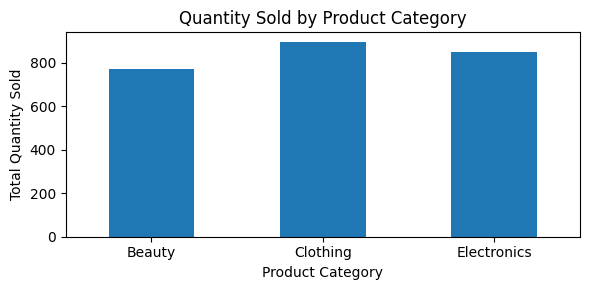

In [40]:
# Quantity Sold by Product Category:

import matplotlib.pyplot as plt

category_quantity.plot(
    kind="bar",
    figsize=(6, 3),
    title="Quantity Sold by Product Category",
    rot=0
)

plt.xlabel("Product Category")
plt.ylabel("Total Quantity Sold")
plt.tight_layout()
plt.show()

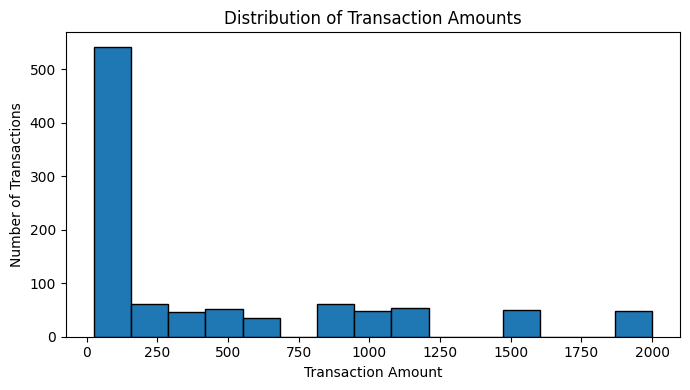

In [41]:
# Sales Distribution Analysis:

# understand how transaction amounts are distributed across the dataset
# This helps the business understand typical customer spending levels and identify opportunities to increase transaction values.

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.hist(
    df["Total Amount"],
    bins=15,
    edgecolor="black"
)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

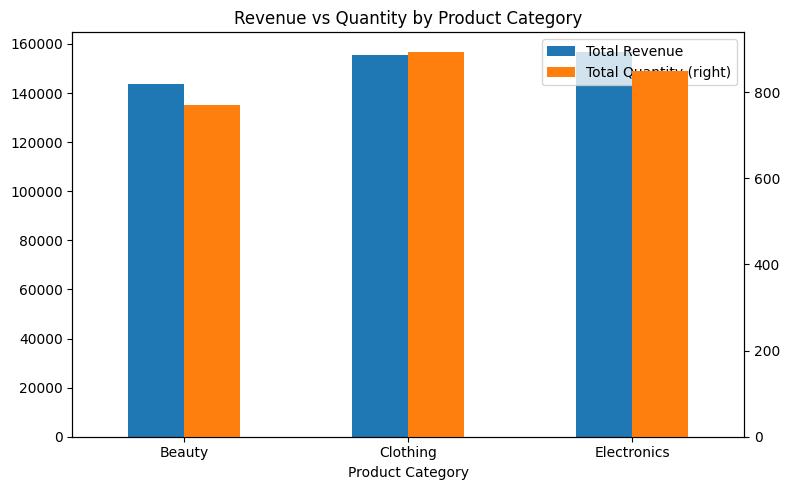

In [42]:
import pandas as pd
import matplotlib.pyplot as plt

# Create the category_comparison DataFrame from existing variables
category_comparison = pd.DataFrame({
    'Total Revenue': category_sales,
    'Total Quantity': category_quantity
})

# Plot the comparison with secondary y-axis for Quantity
category_comparison.plot(
    kind="bar",
    figsize=(8, 5),
    secondary_y="Total Quantity",
    rot=0
)

plt.title("Revenue vs Quantity by Product Category")
plt.xlabel("Product Category")
plt.tight_layout()
plt.show()

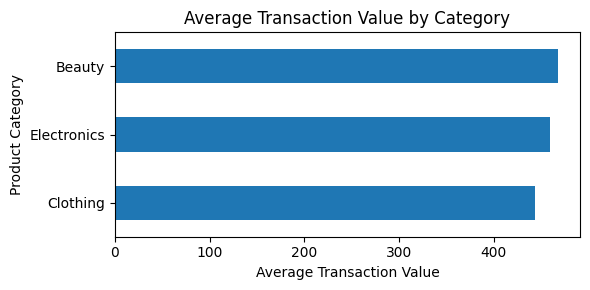

In [43]:
# Average Transaction Value by Product Category:

# This is different from total revenue. It tells us how much customers spend on average per transaction in each category.
import matplotlib.pyplot as plt

# Calculate the average transaction value (mean of 'Total Amount' per category)
avg_transaction = df.groupby("Product Category")["Total Amount"].mean()

plt.figure(figsize=(6, 3))

avg_transaction.sort_values().plot(
    kind="barh"
)

plt.title("Average Transaction Value by Category")
plt.xlabel("Average Transaction Value")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

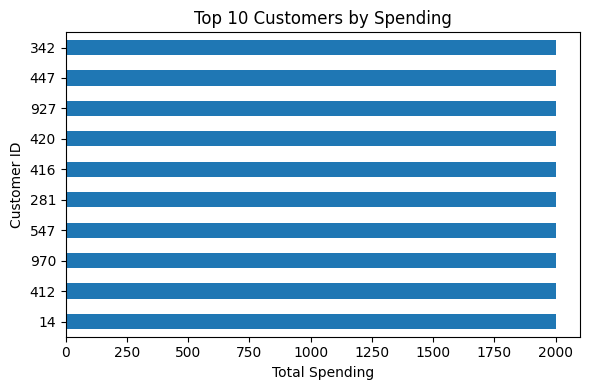

In [44]:
# Top 10 Customers by Spending:

import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))

top_customers.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Customers by Spending")
plt.xlabel("Total Spending")
plt.ylabel("Customer ID")

plt.tight_layout()
plt.show()

In [45]:
df.to_csv("retail_sales_cleaned.csv", index=False)

In [46]:
from google.colab import files
files.download("retail_sales_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [47]:
import os
print(os.getcwd())

/content


In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    1000 non-null   int64         
 1   Date              1000 non-null   datetime64[ns]
 2   Customer ID       1000 non-null   int64         
 3   Gender            1000 non-null   object        
 4   Age               1000 non-null   int64         
 5   Product Category  1000 non-null   object        
 6   Quantity          1000 non-null   int64         
 7   Price per Unit    1000 non-null   int64         
 8   Total Amount      1000 non-null   int64         
 9   Year              1000 non-null   int32         
 10  Month             1000 non-null   int32         
 11  Month Name        1000 non-null   object        
 12  Day               1000 non-null   int32         
 13  Weekday           1000 non-null   object        
dtypes: datetime64[ns](1), int